In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
keys = pd.read_csv('keys/id_map.csv')
returns = pd.read_csv('returns/weekly_returns.csv')

In [ ]:
returns.head()

#### Fix data: convert `week_date` to datetime

In [ ]:
# Convert week_date from string to proper datetime objects
returns['week_date'] = pd.to_datetime(returns['week_date'])

# Attach readable company names via the id map
returns = returns.merge(keys, on='UNIQUE_ID', how='left')

#### Return over time by company

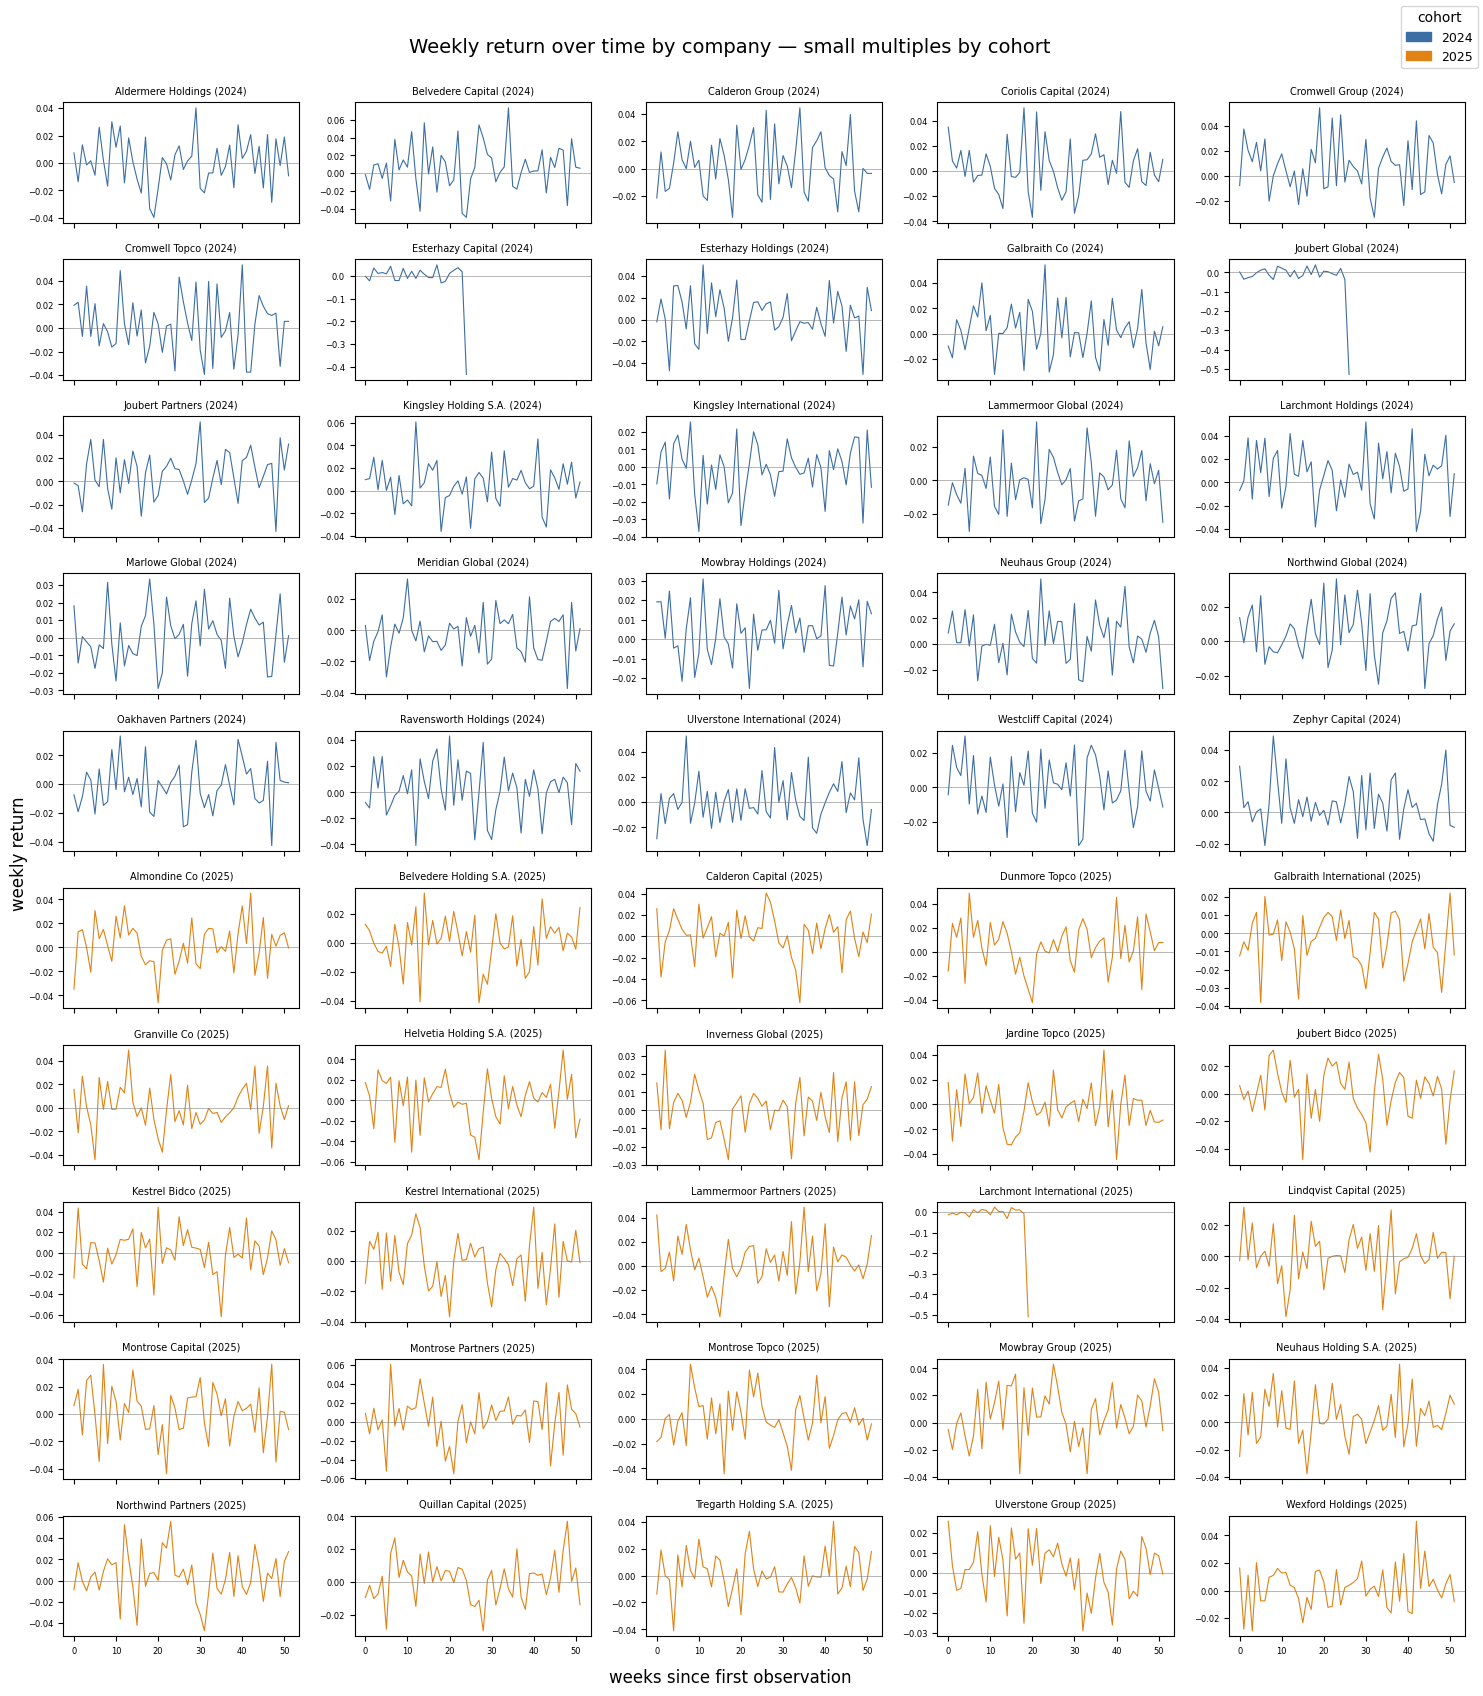

In [ ]:
# Weekly return over time — one small panel per company (small multiples),
# coloured and labelled by cohort (2024 research vs 2025 validation).
# x-axis is event-time: weeks since each issuer's first observation, so panels align.
returns = returns.sort_values(['UNIQUE_ID', 'week_date'])
returns['t'] = returns.groupby('UNIQUE_ID').cumcount()
returns['cohort'] = returns.groupby('UNIQUE_ID')['week_date'].transform('min').dt.year

cohort_color = {2024: '#3b6ea5', 2025: '#e08214'}
# order panels by cohort then name so 2024 issuers cluster before 2025
companies = (returns[['CompanyName', 'cohort']].drop_duplicates()
             .sort_values(['cohort', 'CompanyName'])['CompanyName'].tolist())

ncols = 5
nrows = int(np.ceil(len(companies) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 3, nrows * 1.7), sharex=True)
for ax, name in zip(axes.ravel(), companies):
    g = returns[returns['CompanyName'] == name].sort_values('t')
    coh = int(g['cohort'].iloc[0])
    ax.plot(g['t'], g['return'], lw=0.8, color=cohort_color[coh])
    ax.axhline(0, color='grey', lw=0.4)
    ax.set_title(f"{name} ({coh})", fontsize=7)
    ax.tick_params(labelsize=6)
for ax in axes.ravel()[len(companies):]:   # blank any unused panels
    ax.axis('off')

from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=c, label=str(y)) for y, c in cohort_color.items()],
           title='cohort', loc='upper right', fontsize=9)
fig.supxlabel('weeks since first observation'); fig.supylabel('weekly return')
fig.suptitle('Weekly return over time by company — small multiples by cohort', fontsize=14)
fig.tight_layout(rect=[0, 0, 1, 0.98]); plt.show()

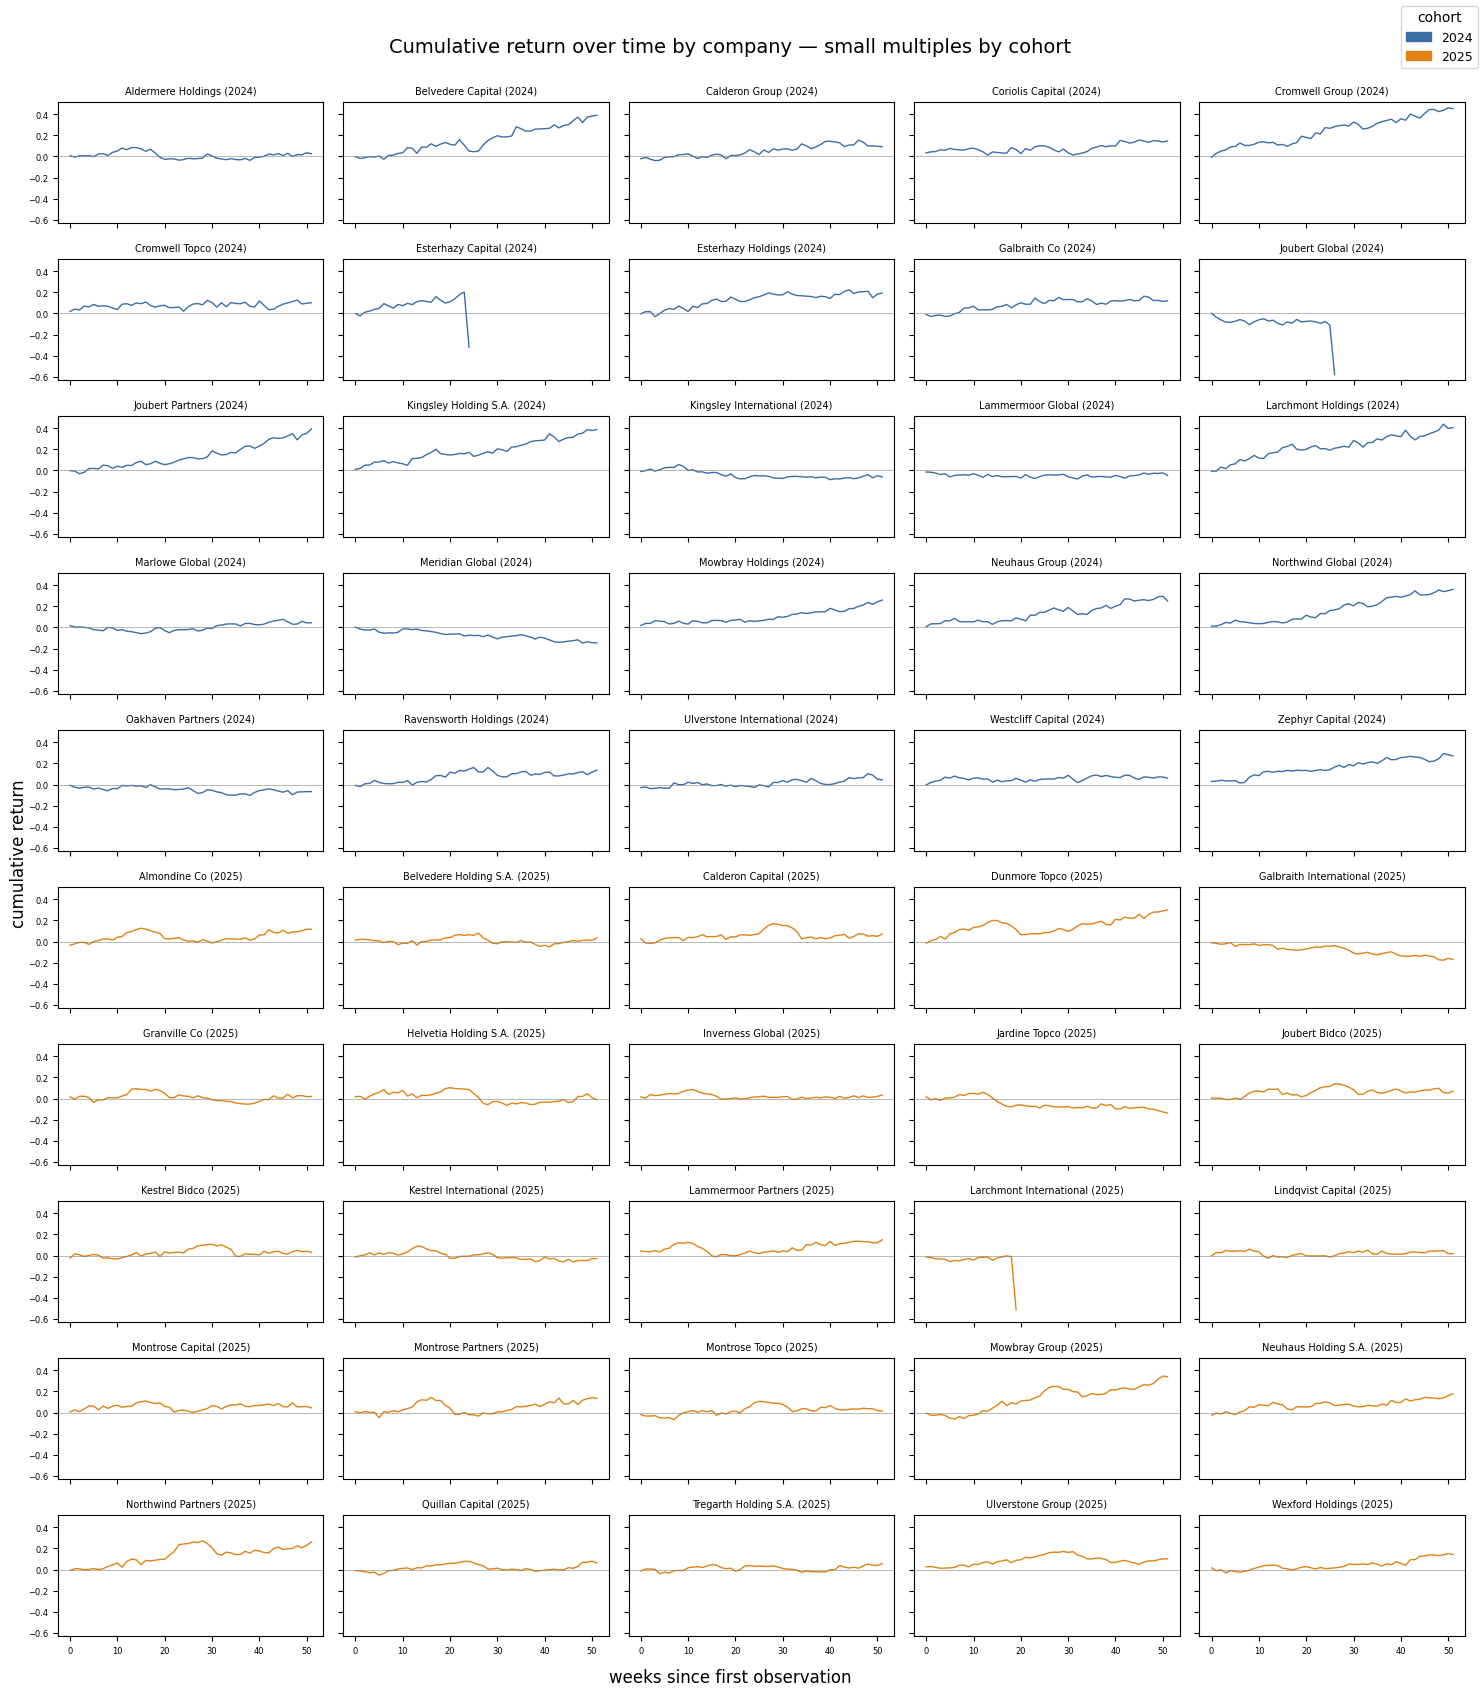

In [ ]:
# Cumulative return over time — one small panel per company (small multiples),
# coloured and labelled by cohort. Cumulative = compounded weekly return,
# (1 + r).cumprod() - 1, along event-time (weeks since first observation).
returns = returns.sort_values(['UNIQUE_ID', 'week_date'])
returns['t'] = returns.groupby('UNIQUE_ID').cumcount()
returns['cohort'] = returns.groupby('UNIQUE_ID')['week_date'].transform('min').dt.year
returns['cum_return'] = returns.groupby('UNIQUE_ID')['return'].transform(lambda r: (1 + r).cumprod() - 1)

cohort_color = {2024: '#3b6ea5', 2025: '#e08214'}
# order panels by cohort then name so 2024 issuers cluster before 2025
companies = (returns[['CompanyName', 'cohort']].drop_duplicates()
             .sort_values(['cohort', 'CompanyName'])['CompanyName'].tolist())

ncols = 5
nrows = int(np.ceil(len(companies) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 3, nrows * 1.7),
                         sharex=True, sharey=True)
for ax, name in zip(axes.ravel(), companies):
    g = returns[returns['CompanyName'] == name].sort_values('t')
    coh = int(g['cohort'].iloc[0])
    ax.plot(g['t'], g['cum_return'], lw=1.0, color=cohort_color[coh])
    ax.axhline(0, color='grey', lw=0.4)
    ax.set_title(f"{name} ({coh})", fontsize=7)
    ax.tick_params(labelsize=6)
for ax in axes.ravel()[len(companies):]:   # blank any unused panels
    ax.axis('off')

from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=c, label=str(y)) for y, c in cohort_color.items()],
           title='cohort', loc='upper right', fontsize=9)
fig.supxlabel('weeks since first observation'); fig.supylabel('cumulative return')
fig.suptitle('Cumulative return over time by company — small multiples by cohort', fontsize=14)
fig.tight_layout(rect=[0, 0, 1, 0.98]); plt.show()

#### Data prep: event-time alignment & cumulative return


In [ ]:
# Event-time index: weeks since each issuer's first observation (t = 0 .. ~51)
returns = returns.sort_values(['UNIQUE_ID', 'week_date'])
returns['t'] = returns.groupby('UNIQUE_ID').cumcount()

# Collapse each issuer's series to one number: compounded cumulative total return
summary = returns.groupby('UNIQUE_ID').agg(
    CompanyName=('CompanyName', 'first'),
    start=('week_date', 'min'),
    end=('week_date', 'max'),
    n_weeks=('week_date', 'size'),
    cum_return=('return', lambda x: (1 + x).prod() - 1),
).reset_index()

# Cohort: 2024 = research set, 2025 = validation set (start year == presentation year)
summary['cohort'] = summary['start'].dt.year
# Early-terminated series (< 1 year) -> the three names that blew up
summary['terminated'] = summary['n_weeks'] < 52

summary.sort_values('cum_return').reset_index(drop=True).head()

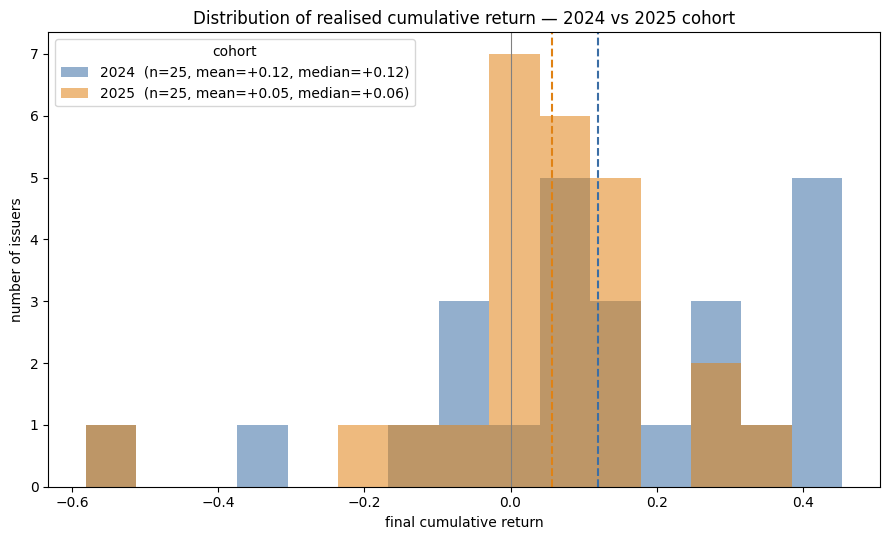

In [ ]:
# Plot cumulative return distribution by cohort
# One number per issuer: compounded total return over its observation window,
# split into the 2024 research cohort vs the 2025 validation cohort.
final = (returns.groupby(['UNIQUE_ID', 'cohort'])['return']
                .apply(lambda r: (1 + r).prod() - 1)
                .rename('final_cum_return').reset_index())

cohort_color = {2024: '#3b6ea5', 2025: '#e08214'}
bins = np.linspace(final['final_cum_return'].min(), final['final_cum_return'].max(), 16)

fig, ax = plt.subplots(figsize=(9, 5.5))
for coh, g in final.groupby('cohort'):
    ax.hist(g['final_cum_return'], bins=bins, alpha=0.55, color=cohort_color[coh],
            label=f'{coh}  (n={len(g)}, mean={g["final_cum_return"].mean():+.2f}, '
                  f'median={g["final_cum_return"].median():+.2f})')
    ax.axvline(g['final_cum_return'].median(), color=cohort_color[coh], ls='--', lw=1.5)
ax.axvline(0, color='grey', lw=0.8)
ax.set_xlabel('final cumulative return'); ax.set_ylabel('number of issuers')
ax.set_title('Distribution of realised cumulative return — 2024 vs 2025 cohort')
ax.legend(title='cohort'); fig.tight_layout(); plt.show()

## Presentation features — load, visualise & value-check the extraction

In [ ]:
# Load the structured extraction produced by extraction/extract.py
feat = pd.read_csv('extraction/extracted.csv')
print('shape:', feat.shape)
print('\ncolumns:', list(feat.columns))
feat.head(5)

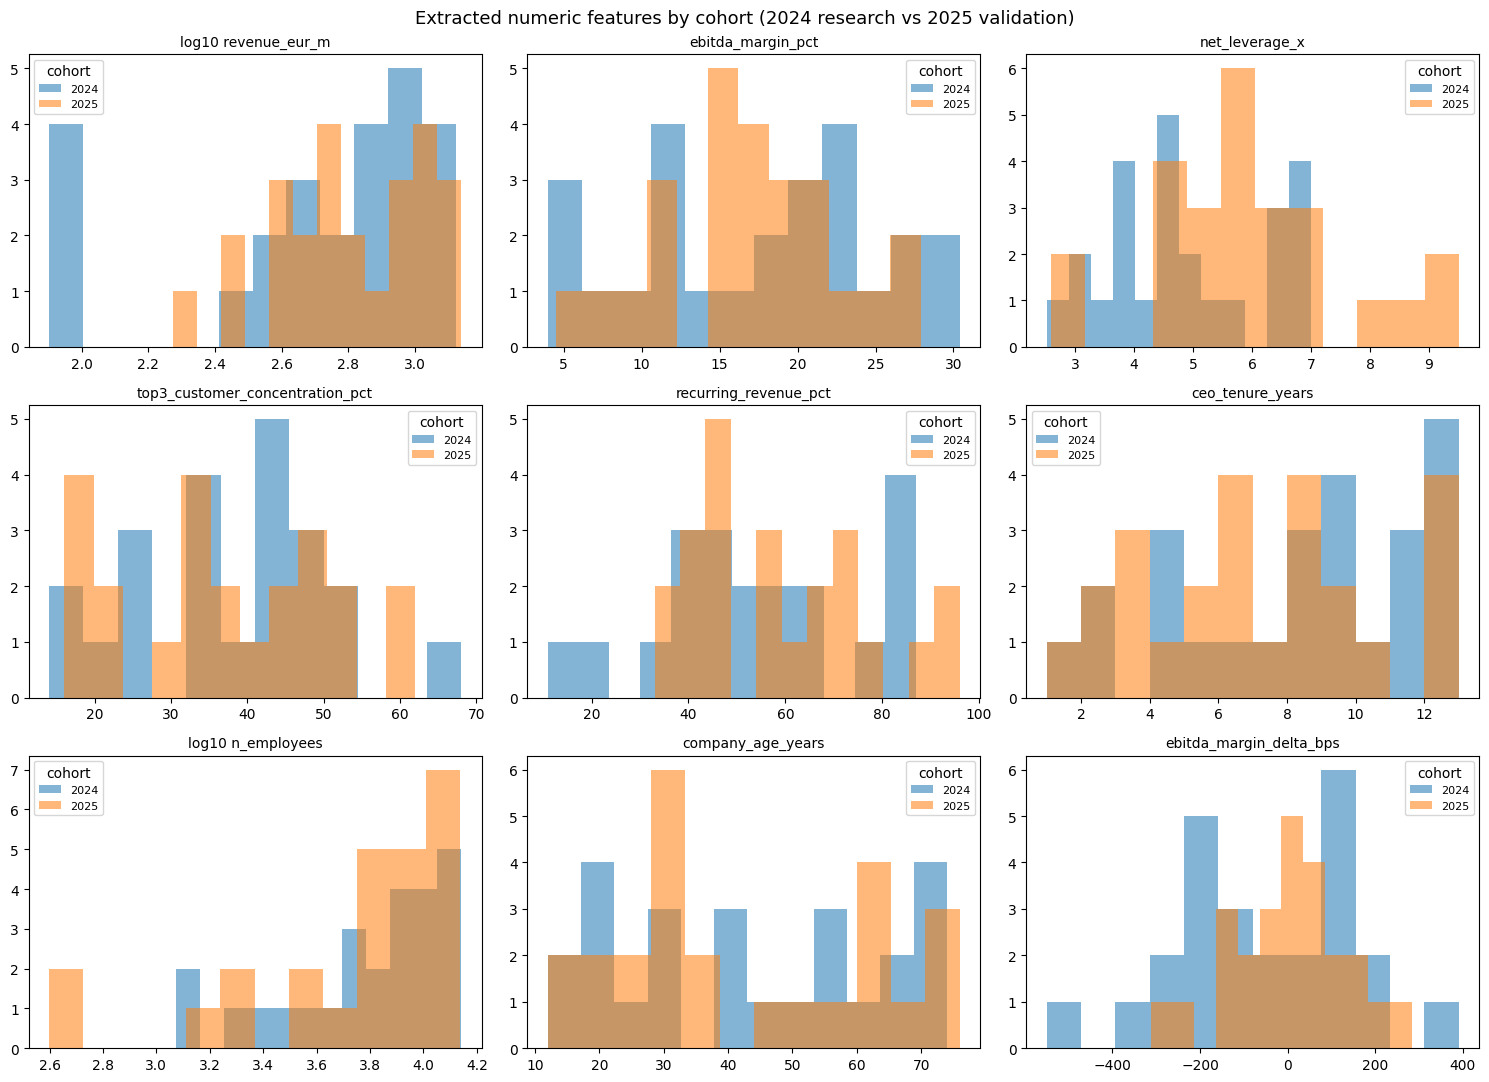

In [ ]:
# Numeric features — distributions, 2024 research vs 2025 validation cohort
num_cols = ['revenue_eur_m', 'ebitda_margin_pct', 'net_leverage_x',
            'top3_customer_concentration_pct', 'recurring_revenue_pct',
            'ceo_tenure_years', 'n_employees', 'company_age_years',
            'ebitda_margin_delta_bps']
log_cols = {'revenue_eur_m', 'n_employees'}
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, col in zip(axes.ravel(), num_cols):
    for coh, g in feat.groupby('cohort'):
        data = g[col].dropna()
        if col in log_cols:
            data = np.log10(data)
        ax.hist(data, bins=12, alpha=0.55, label=str(coh))
    ax.set_title(('log10 ' if col in log_cols else '') + col, fontsize=10)
    ax.legend(title='cohort', fontsize=8)
fig.suptitle('Extracted numeric features by cohort (2024 research vs 2025 validation)',
             fontsize=13)
fig.tight_layout(); plt.show()

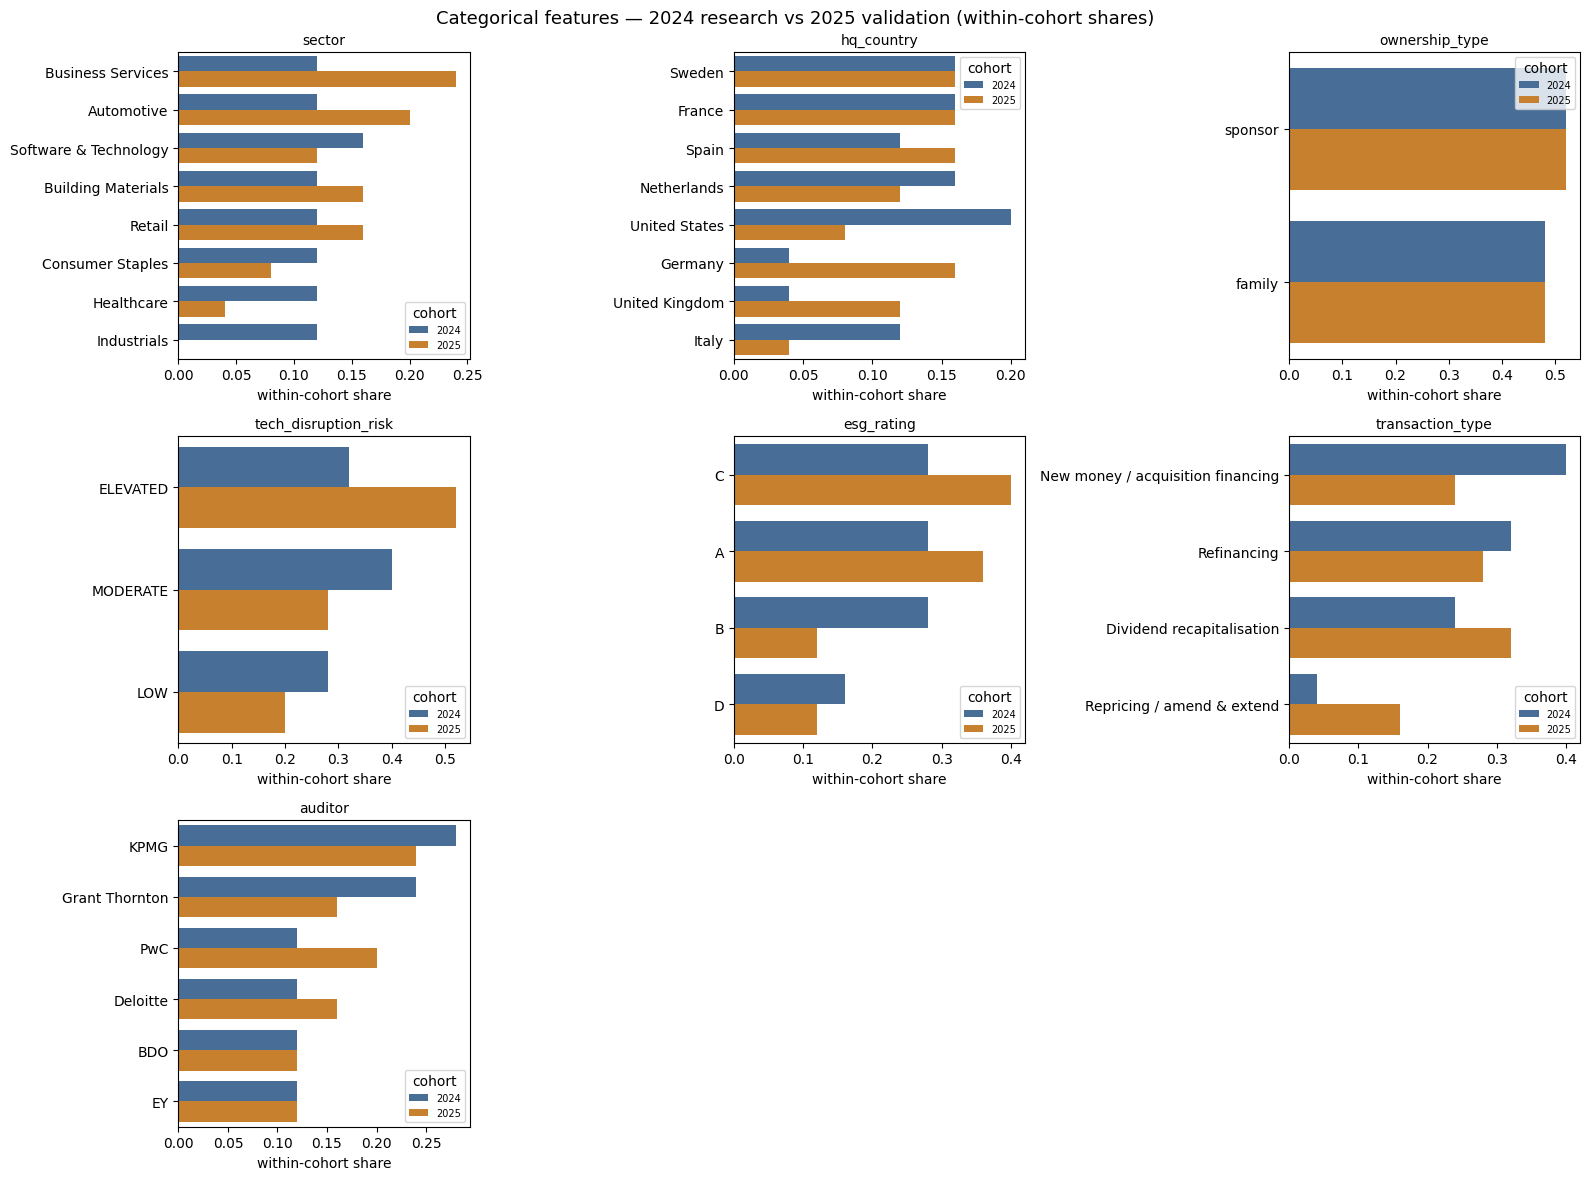

In [ ]:
#  Categorical features — 2024 research vs 2025 validation distribution check.
# Both cohorts hold 25 issuers, so we compare WITHIN-cohort shares to see whether
# the validation set is drawn from roughly the same distribution as the training set.
cat_cols = ['sector', 'hq_country', 'ownership_type', 'tech_disruption_risk',
            'esg_rating', 'transaction_type', 'auditor']

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
for ax, col in zip(axes.ravel(), cat_cols):
    # within-cohort proportion so the two 25-name cohorts are directly comparable
    prop = (feat.groupby('cohort')[col].value_counts(normalize=True)
                .rename('proportion').reset_index())
    order = feat[col].value_counts().index  # order levels by overall frequency
    sns.barplot(data=prop, x='proportion', y=col, hue='cohort', order=order,
                ax=ax, palette={2024: '#3b6ea5', 2025: '#e08214'})
    ax.set_title(col, fontsize=10); ax.set_xlabel('within-cohort share'); ax.set_ylabel('')
    ax.legend(title='cohort', fontsize=7)
for ax in axes.ravel()[len(cat_cols):]:
    ax.axis('off')
fig.suptitle('Categorical features — 2024 research vs 2025 validation (within-cohort shares)',
             fontsize=13)
fig.tight_layout(); plt.show()

## Signal exploration — univariate Spearman vs 2024 return (research set)

For each extracted feature, how strongly does it rank-correlate with the realised **2024** cumulative return? Negative rho = a higher feature value goes with a *worse* return. Ordinal/binary fields (ownership, ESG, disruption risk) are encoded to numbers so they can be rank-correlated. 2025 is deliberately left untouched.

In [ ]:
# Univariate signal check on the 2024 research set only (2025 stays sealed).
from scipy.stats import spearmanr

# Research-set master: extracted features joined to the realised return series.
# Drop feat's 'cohort' (presentation year) so summary's cohort (return start year) is used.
research = summary.merge(feat.drop(columns=['cohort']),
                         left_on='UNIQUE_ID', right_on='unique_id')
research = research[research['cohort'] == 2024].copy()

# Encode ordinal / binary categoricals so they can be rank-correlated.
research['ownership_sponsor'] = (research['ownership_type'] == 'sponsor').astype(int)
research['risk_ord'] = research['tech_disruption_risk'].map({'LOW': 0, 'MODERATE': 1, 'ELEVATED': 2})
research['esg_ord'] = research['esg_rating'].map({'A': 4, 'B': 3, 'C': 2, 'D': 1})

candidates = ['net_leverage_x', 'ebitda_margin_pct', 'ebitda_margin_delta_bps',
              'revenue_eur_m', 'ceo_tenure_years','ebitda_eur_m', 'ebitda_margin_prior_pct', 'net_debt_eur_m']

# 'n_employees', 'n_sites', 'founded_year','company_age_years','top3_customer_concentration_pct', 'recurring_revenue_pct','ownership_sponsor', 'risk_ord', 'esg_ord', 

rows = []
for c in candidates:
    sub = research[[c, 'cum_return']].dropna()
    rho, p = spearmanr(sub[c], sub['cum_return'])
    rows.append({'feature': c, 'spearman_rho': np.round(rho, 3),
                 'p_value': np.round(p, 3), 'n': len(sub)})

uni = pd.DataFrame(rows)
uni = (uni.assign(_a=uni['spearman_rho'].abs())
          .sort_values('_a', ascending=False)
          .drop(columns='_a')
          .reset_index(drop=True))
uni

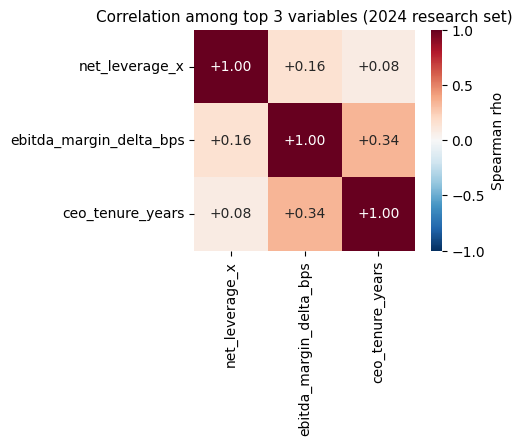

In [ ]:
# Check if net_leverage_x, ceo_tenure_years, ebitda_margin_delta_bp are correlated with each other
drivers = ['net_leverage_x', 'ebitda_margin_delta_bps', 'ceo_tenure_years']
D = research[drivers].dropna()
print(f"Pairwise Spearman rank correlation among the model drivers (2024 set, n={len(D)}):\n")
corr = D.corr(method='spearman')

# p-values for each pair
for i, a in enumerate(drivers):
    for b in drivers[i + 1:]:
        rho, p = spearmanr(D[a], D[b])
        flag = '  <-- notable' if abs(rho) >= 0.4 else ''
        print(f"  {a:26} vs {b:26} rho={rho:+.3f}  p={p:.3f}{flag}")

# Heatmap
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(corr, annot=True, fmt='+.2f', cmap='RdBu_r', vmin=-1, vmax=1,
            square=True, cbar_kws={'label': 'Spearman rho'}, ax=ax)
ax.set_title('Correlation among top 3 variables (2024 research set)', fontsize=11)
fig.tight_layout(); plt.show()

## Risk model — z-score blend

A single risk score per issuer:

**risk = z(net leverage) − z(EBITDA margin trend)**

where z() standardises each feature within the cohort (subtract mean, divide by SD).
Higher leverage and a weaker margin trend both push the score up (riskier), so we expect a
**negative** Spearman correlation with realised cumulative return. The score is built on the
2024 training set and then applied unchanged to the sealed 2025 validation set (standardised
within each cohort, no refitting).

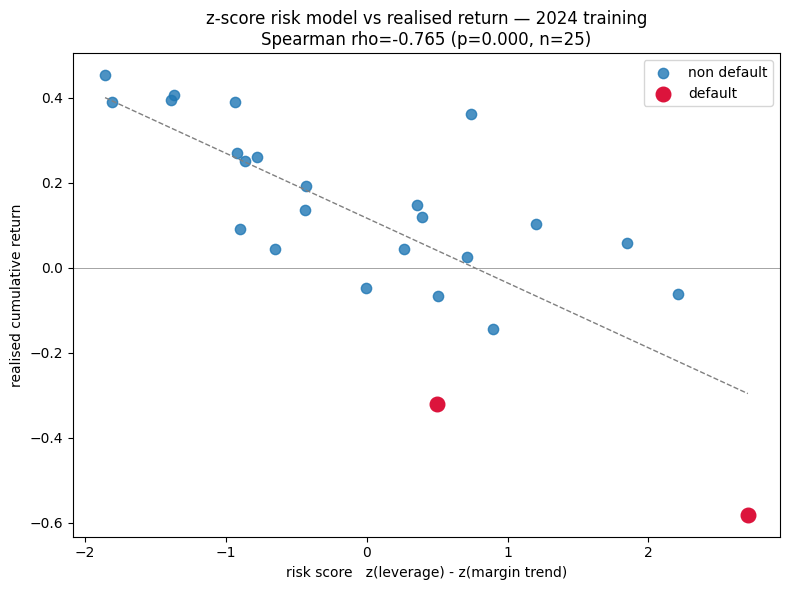

In [ ]:
# ── Risk model: z-score blend  risk = z(leverage) - z(ebitda_margin_delta_bps) ──
# Standardise each driver within the cohort (subtract mean / divide by SD) and combine on
# the z-scale. Higher leverage -> riskier; weaker margin trend -> riskier (hence minus).
# Evaluate with Spearman vs realised cumulative return: 2024 training, then the frozen 2025
# validation (spec unchanged, standardised within each cohort, no refitting).
from scipy.stats import spearmanr

def zscore(s):
    return (s - s.mean()) / s.std()

def build_risk_frame(cohort_year):
    df = summary.merge(feat.drop(columns=['cohort']),
                       left_on='UNIQUE_ID', right_on='unique_id')
    df = df[df['cohort'] == cohort_year].copy()
    df['risk_score'] = zscore(df['net_leverage_x']) - zscore(df['ebitda_margin_delta_bps'])
    df['terminated'] = df['n_weeks'] < 52
    return df

train = build_risk_frame(2024)   # in-sample: where the model is built
valid = build_risk_frame(2025)   # out-of-time hold-out: untouched until validation

print("Risk model:  risk = z(leverage) - z(ebitda_margin_delta_bps)")
print("Spearman of risk score vs realised cumulative return (negative = ranks correctly):\n")
for label, df in [("2024 training  (in-sample)", train), ("2025 validation (out-of-time)", valid)]:
    d = df.dropna(subset=['risk_score', 'cum_return'])
    rho, p = spearmanr(d['risk_score'], d['cum_return'])
    print(f"  {label:32} rho={rho:+.3f}  p={p:.3f}  n={len(d)}")

# ---- scatter: risk score vs realised return (2024 training) ----
d = train.dropna(subset=['risk_score', 'cum_return'])
rho, p = spearmanr(d['risk_score'], d['cum_return'])
normal = d[~d['terminated']]; term = d[d['terminated']]

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(normal['risk_score'], normal['cum_return'], s=55, alpha=0.8, label='non default')
ax.scatter(term['risk_score'], term['cum_return'], s=110, color='crimson',
           label='default')
b, a = np.polyfit(d['risk_score'], d['cum_return'], 1)
xs = np.linspace(d['risk_score'].min(), d['risk_score'].max(), 10)
ax.plot(xs, a + b * xs, 'grey', ls='--', lw=1)
ax.axhline(0, color='grey', lw=0.5)
ax.set_title(f"z-score risk model vs realised return — 2024 training\n"
             f"Spearman rho={rho:+.3f} (p={p:.3f}, n={len(d)})", fontsize=12)
ax.set_xlabel('risk score   z(leverage) - z(margin trend)')
ax.set_ylabel('realised cumulative return')
ax.legend(); fig.tight_layout(); plt.show()

## Validation — bootstrap & risk tiers (2025 hold-out)

The z-score model is frozen and tested out-of-time on 2025. Below: a bootstrap CI for the
validation Spearman rho (resample issuers, re-standardise within each resample), then the
issuers split into three risk tiers with the high- and low-risk names listed. All 25 names
are kept, including the terminated (<52-week) ones.

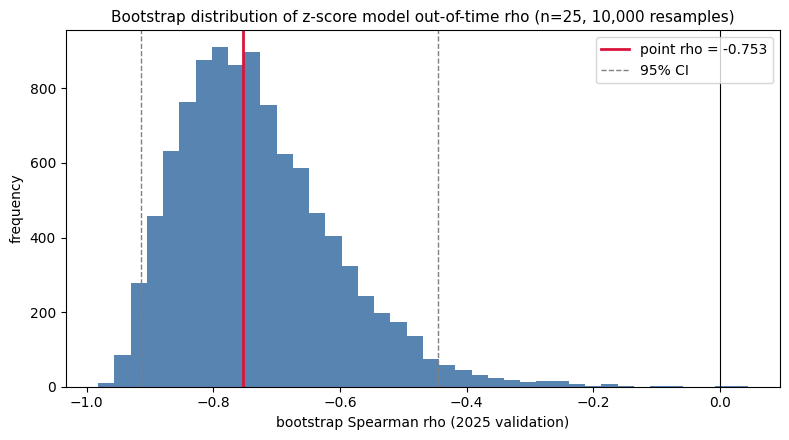

In [ ]:
# ── Bootstrap CI for the 2025 out-of-time rho (z-score risk model) ──
# Resample the validation issuers WITH replacement, RE-STANDARDISE within each resample
# (so the z-scoring uncertainty is propagated too), recompute the risk score and Spearman.
# All names kept, terminated included. Report the percentile CI and sign reliability.
rng = np.random.default_rng(42)
N_BOOT = 10_000

base = valid[['net_leverage_x', 'ebitda_margin_delta_bps', 'cum_return']].dropna().reset_index(drop=True)
n = len(base)

boot = np.empty(N_BOOT)
for i in range(N_BOOT):
    idx = rng.integers(0, n, n)
    s = base.iloc[idx]
    risk = zscore(s['net_leverage_x']) - zscore(s['ebitda_margin_delta_bps'])
    boot[i], _ = spearmanr(risk, s['cum_return'])

boot = boot[~np.isnan(boot)]                      # drop degenerate resamples (zero-variance feature)
lo, hi = np.percentile(boot, [2.5, 97.5])
point, _ = spearmanr(zscore(base['net_leverage_x']) - zscore(base['ebitda_margin_delta_bps']),
                     base['cum_return'])

print("z-score risk model — 2025 out-of-time bootstrap")
print(f"  point rho                    = {point:+.3f}")
print(f"  bootstrap mean               = {boot.mean():+.3f}")
print(f"  95% percentile CI            = [{lo:+.3f}, {hi:+.3f}]   ({len(boot):,} valid resamples, n={n})")
print(f"  share of resamples rho < 0   = {(boot < 0).mean():.1%}   (want this high for a robust negative signal)")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(boot, bins=40, color='#3b6ea5', alpha=0.85)
ax.axvline(point, color='crimson', lw=2, label=f'point rho = {point:+.3f}')
ax.axvline(lo, color='grey', ls='--', lw=1)
ax.axvline(hi, color='grey', ls='--', lw=1, label='95% CI')
ax.axvline(0, color='black', lw=0.8)
ax.set_xlabel('bootstrap Spearman rho (2025 validation)'); ax.set_ylabel('frequency')
ax.set_title(f'Bootstrap distribution of z-score model out-of-time rho (n={n}, {N_BOOT:,} resamples)',
             fontsize=11)
ax.legend(); fig.tight_layout(); plt.show()

In [ ]:
# ── Divide the 2025 z-score risk score into three tiers ──
# Within-cohort terciles of the frozen risk score (higher score = model says riskier).
# All 25 validation names kept, terminated included. Then inspect realised return by tier.
tier_labels = ['Low risk', 'Medium risk', 'High risk']

v = valid.dropna(subset=['risk_score', 'cum_return']).copy()
# rank(method='first') -> unique ranks so qcut makes three clean, equal-sized buckets
v['tier'] = pd.qcut(v['risk_score'].rank(method='first'), 3, labels=tier_labels)
v['tier'] = pd.Categorical(v['tier'], categories=tier_labels, ordered=True)

# Tier summary — mean AND median (means get dragged by the blow-ups, so show both)
tier_tbl = (v.groupby('tier', observed=True)['cum_return']
              .agg(n='size', mean_return='mean', median_return='median')
              .reset_index())
print("2025 validation — realised return by z-score risk tier (higher tier = model says riskier):")
print(tier_tbl.to_string(index=False))


# ---- names in the two extreme tiers ----
cols = ['CompanyName', 'net_leverage_x', 'ebitda_margin_delta_bps', 'risk_score', 'cum_return', 'terminated']
for tlabel in ['High risk', 'Low risk']:
    grp = v[v['tier'] == tlabel].sort_values('risk_score', ascending=False)[cols]
    print(f"\n{tlabel} tier — {len(grp)} names (sorted by model risk score, riskiest first):")
    print(grp.to_string(index=False))